In [1]:
import os, sys

REPO = "GROUP41_CENG313"
if not os.path.exists(REPO):
    !git clone -q https://github.com/OmerNuriZ/{REPO}.git
else:
    !git -C {REPO} pull -q

sys.path.insert(0, f"{REPO}/src")

In [2]:
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!pip -q install -U kaggle
!kaggle competitions download -c csiro-biomass -p data
!unzip -q -o data/csiro-biomass.zip -d data
!ls data

csiro-biomass.zip: Skipping, found more recently modified local copy (use --force to force download)
csiro-biomass.zip  sample_submission.csv  test	test.csv  train  train.csv


In [3]:
from data import load_train

df = load_train("data/train.csv")
print(df.shape)
df.head()

(357, 11)


,image_path,Sampling_Date,State,Species,Pre_GSHH_NDVI,Height_Ave_cm,Dry_Green_g,Dry_Dead_g,Dry_Clover_g,GDM_g,Dry_Total_g
0,train/ID1011485656.jpg,2015/9/4,Tas,Ryegrass_Clover,0.62,4.6667,16.2751,31.9984,0.0000,16.2750,48.2735
1,train/ID1012260530.jpg,2015/4/1,NSW,Lucerne,0.55,16.0000,7.6000,0.0000,0.0000,7.6000,7.6000
2,train/ID1025234388.jpg,2015/9/1,WA,SubcloverDalkeith,0.38,1.0000,0.0000,0.0000,6.0500,6.0500,6.0500
3,train/ID1028611175.jpg,2015/5/18,Tas,Ryegrass,0.66,5.0000,24.2376,30.9703,0.0000,24.2376,55.2079
4,train/ID1035947949.jpg,2015/9/11,Tas,Ryegrass,0.54,3.5000,10.5261,23.2239,0.4343,10.9605,34.1844


## 1. Target Analizi

In [4]:
from data import TARGETS

print(df[TARGETS].describe().round(1))
print("\nSıfır oranları:")
print((df[TARGETS] == 0).mean().round(3))

       Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
count        357.0       357.0         357.0  357.0        357.0
mean          26.6        12.0           6.6   33.3         45.3
std           25.4        12.4          12.1   24.9         28.0
min            0.0         0.0           0.0    1.0          1.0
25%            8.8         3.2           0.0   16.0         25.3
50%           20.8         8.0           1.4   27.1         40.3
75%           35.1        17.6           7.2   43.7         57.9
max          158.0        83.8          71.8  158.0        185.7

Sıfır oranları:
Dry_Green_g     0.050
Dry_Dead_g      0.112
Dry_Clover_g    0.378
GDM_g           0.000
Dry_Total_g     0.000
dtype: float64


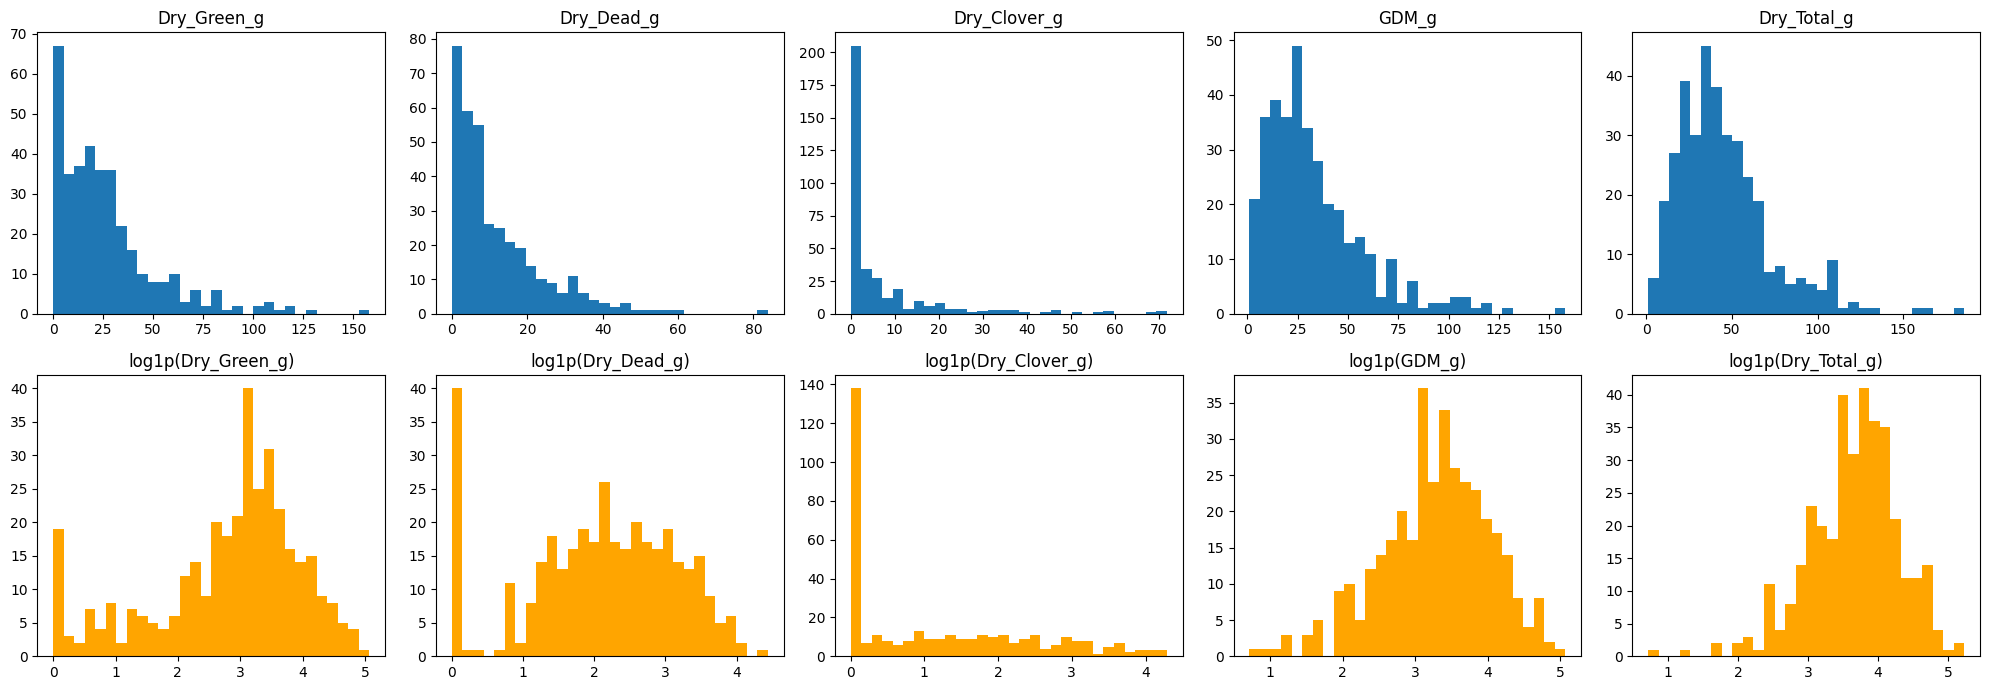

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 5, figsize=(20, 7))
for i, t in enumerate(TARGETS):
    ax[0, i].hist(df[t], bins=30)
    ax[0, i].set_title(t)
    ax[1, i].hist(np.log1p(df[t]), bins=30, color="orange")
    ax[1, i].set_title(f"log1p({t})")
plt.tight_layout()
plt.show()

**Yorum:**
- Tüm hedefler sağa çarpık: Dry_Total medyan 40.3 g, max 185.7 g
- Log1p sonrası GDM ve Dry_Total neredeyse simetrik, modelleri log ölçeğinde eğitmeliyiz.
- Dry_Green ve Dry_Dead'de 0'da ayrı bir yığılma var.
- Dry_Clover'ın %37.8'i sıfır, en zor hedef bu olacak.

## 2. Hedefler Arası İlişki

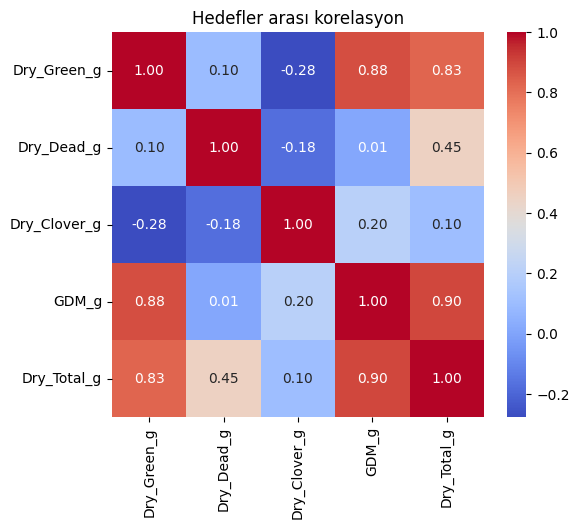

In [6]:
import seaborn as sns

plt.figure(figsize=(6, 5))
sns.heatmap(df[TARGETS].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Hedefler arası korelasyon")
plt.show()

In [7]:
fark_total = df["Dry_Total_g"] - (df["Dry_Green_g"] + df["Dry_Dead_g"] + df["Dry_Clover_g"])
fark_gdm = df["GDM_g"] - (df["Dry_Green_g"] + df["Dry_Clover_g"])

print("Total - (Green+Dead+Clover) max fark:", round(fark_total.abs().max(), 3))
print("GDM - (Green+Clover) max fark:", round(fark_gdm.abs().max(), 3))

Total - (Green+Dead+Clover) max fark: 0.309
GDM - (Green+Clover) max fark: 0.0


**Yorum:**
- Dry_Total = Green + Dead + Clover (max fark 0.31 g), GDM = Green + Clover (fark 0).
- Yani 5 hedefin aslında 3'ü bağımsız, diğer ikisi toplamdan geliyor.
- En güçlü korelasyon GDM ile Total arasında (0.90), sonra Green ile GDM (0.88).
- Clover diğerlerinden ayrı davranıyor, korelasyonları zayıf hatta negatif.

## 3. Metadata Analizi
Bu alanlar sadece train'de var, test'te yok. Model yalnızca görüntüyü görecek.

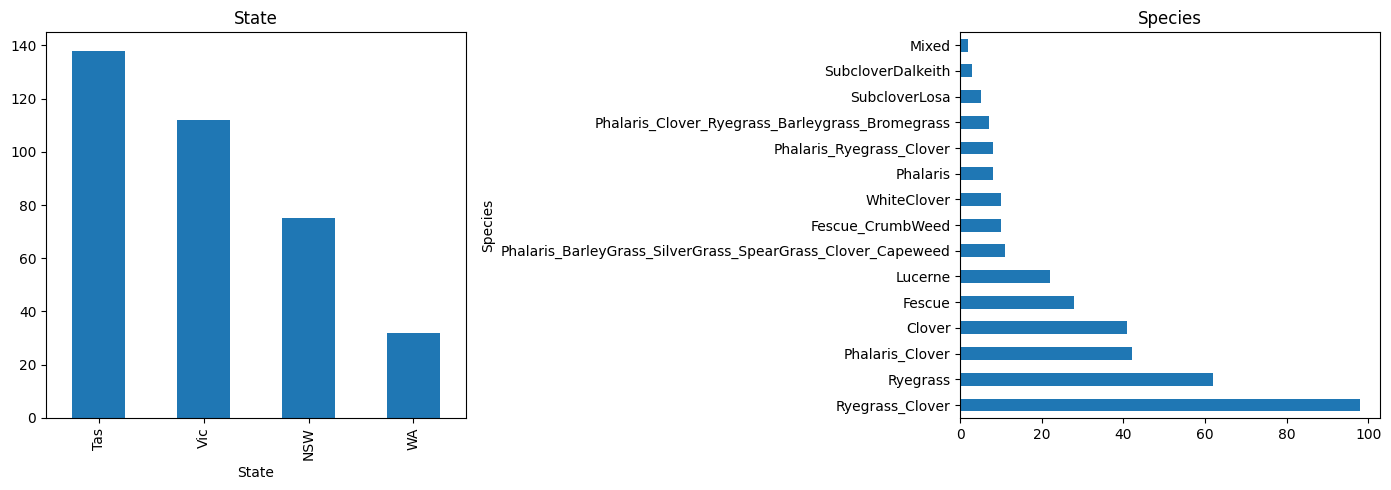

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
df["State"].value_counts().plot.bar(ax=ax[0], title="State")
df["Species"].value_counts().plot.barh(ax=ax[1], title="Species")
plt.tight_layout()
plt.show()

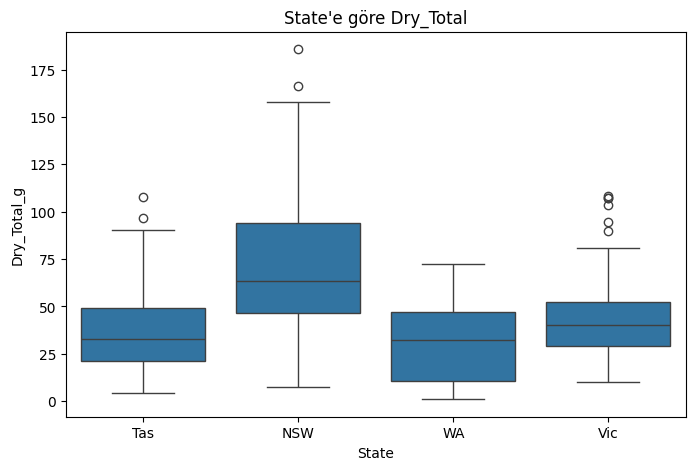

       Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
State                                                           
NSW           53.5         8.4           0.0   53.5         63.3
Tas           13.0        11.1           1.1   18.3         32.8
Vic           21.6         7.2           4.1   27.9         40.2
WA             0.4         0.0          15.6   32.3         32.3


In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="State", y="Dry_Total_g")
plt.title("State'e göre Dry_Total")
plt.show()

print(df.groupby("State")[TARGETS].median().round(1))

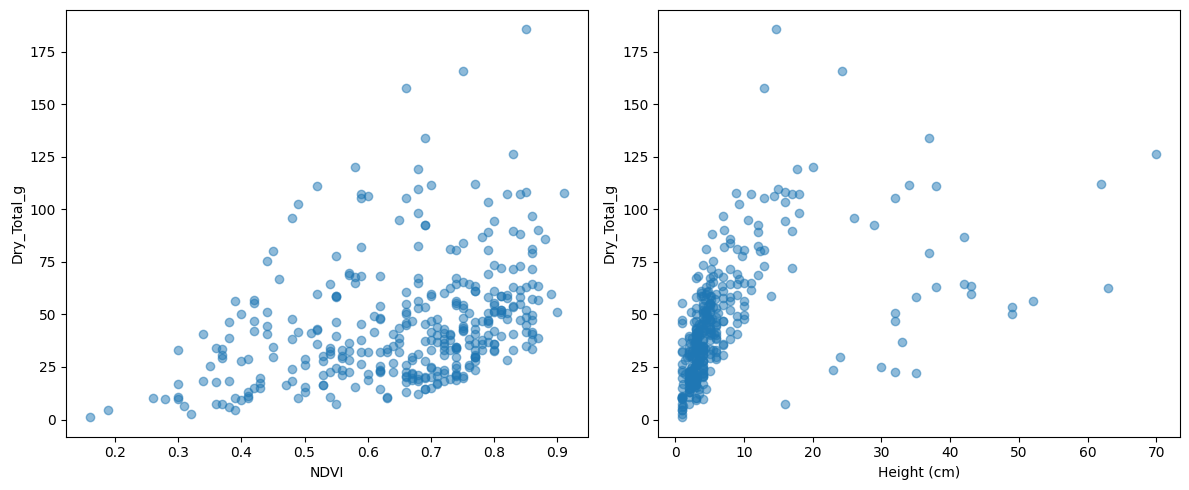

               Dry_Green_g  Dry_Dead_g  Dry_Clover_g  GDM_g  Dry_Total_g
Pre_GSHH_NDVI         0.45       -0.12          0.14   0.59         0.42
Height_Ave_cm         0.80        0.21         -0.45   0.69         0.73


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].scatter(df["Pre_GSHH_NDVI"], df["Dry_Total_g"], alpha=0.5)
ax[0].set_xlabel("NDVI")
ax[0].set_ylabel("Dry_Total_g")

ax[1].scatter(df["Height_Ave_cm"], df["Dry_Total_g"], alpha=0.5)
ax[1].set_xlabel("Height (cm)")
ax[1].set_ylabel("Dry_Total_g")

plt.tight_layout()
plt.show()

cols = ["Pre_GSHH_NDVI", "Height_Ave_cm"]
corr = df[cols + TARGETS].corr(method="spearman")
print(corr.loc[cols, TARGETS].round(2))

**Yorum:**
- Örnek sayıları State'e göre dengesiz: Tas 138, Vic 112, NSW 75, WA 32. 15 farklı tür var, en çok Ryegrass_Clover.
- NSW'de biomass belirgin şekilde yüksek (medyan Total 63 g, Tas'ta 33 g). WA örneklerinde neredeyse sadece Clover var.
- Height ile Total arasında güçlü ilişki var (0.73), NDVI'da daha zayıf (0.42).
- Aynı yerden ve tarihten gelen fotoğraflar birbirine benzediği için CV'de GroupKFold kullanacağız.